# Physics residuals and saved neural models

Represent $u=a+ib$ and enforce both real residuals. Parameter positivity comes from log coefficients. A stored checkpoint can be evaluated without retraining.

All measurements here are synthetic. This notebook runs a small independent calculation and then inspects a retained study figure. It does not launch full training or overwrite the saved scientific results.

In [1]:

from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists() and (p / "src/optics_portfolio").exists())
%matplotlib inline

PROJECT = ROOT


## Calculate and inspect

Read the calculation before executing. Compare numerical values with the stated physical assumptions.

In [2]:
import torch
from optics_portfolio.inverse import make_pinn
metadata=json.loads((PROJECT/"results/advanced_metrics.json").read_text())
seed=metadata["config"]["seeds"][0]
checkpoint=torch.load(PROJECT/f"results/joint_inverse_seed{seed}.pt",map_location="cpu",weights_only=True)
model=make_pinn(seed,checkpoint["width"])
model.load_state_dict(checkpoint["state_dict"])
print("Learned d,g:",model.log_d.exp().item(),model.log_g.exp().item())
print("Training budget:",checkpoint["adam_steps"],"Adam +",checkpoint["lbfgs_steps"],"LBFGS")

Learned d,g: 0.8675861358642578 1.1840226650238037
Training budget: 3000 Adam + 40 LBFGS


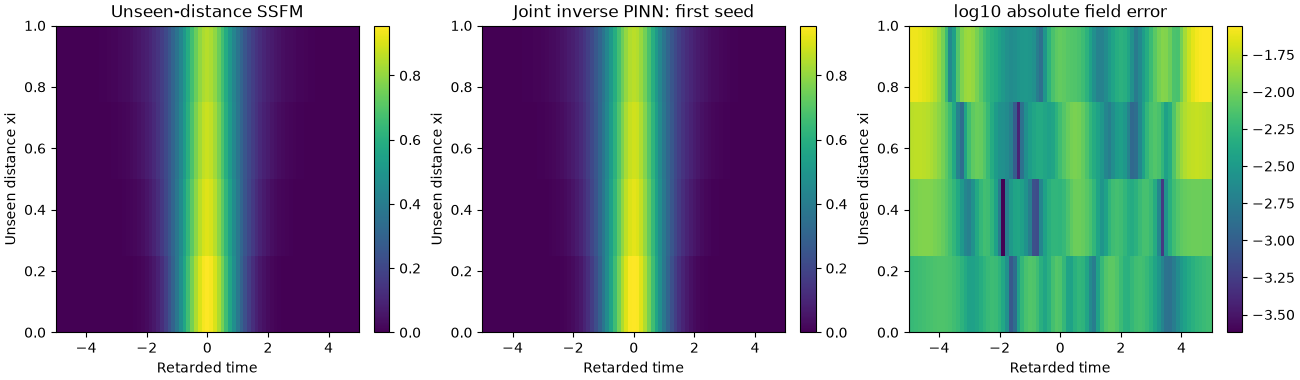

In [3]:
display(Image(filename=str(PROJECT / "results/unseen_distance_comparison.png")))

## Interpret and extend

Derive the residual signs by substituting a+ib into the NLSE. Explain why tanh is appropriate for second spatial derivatives, and distinguish supervised labels from collocation points.

See `../report/technical_report.md` and the project README for the full experiment and limitations. Record your own changed settings and conclusions in a separate run.